*    Evaluate the trained SVM model using the test set
*    Calculate the accuracy score and confusion matrix

# Image Classification using CNN

*   Creating deep networks using Keras
*   Training a neural network
*   Prediction and performance analysis using neural networks
*   Using pre-trained networks
*   Feature visualizations
---

# **Colaboratory environment**
By default, Colab notebooks run on CPU.
You can switch your notebook to run with GPU.

In order to obtain access to the GPU, you need to choose the tab Runtime and then select “Change runtime type” as shown in the following figure:

![Changing runtime](https://miro.medium.com/max/747/1*euE7nGZ0uJQcgvkpgvkoQg.png)

When a pop-up window appears select GPU. Ensure “Hardware accelerator” is set to GPU.

In [1]:
# Loading necessary libraries (Feel free to add new libraries if you need for any computation)
import numpy as np
from matplotlib import pyplot as plt
from tensorflow import keras

# **Working with a new dataset: CIFAR-10**

The CIFAR-10 dataset consists of 60000 32x32 colour images in 10 classes, with 6000 images per class. There are 50000 training images and 10000 test images. More information about CIFAR-10 can be found [here](https://www.cs.toronto.edu/~kriz/cifar.html).

In Keras, the CIFAR-10 dataset is also preloaded in the form of four Numpy arrays. x_train and y_train contain the training set, while x_test and y_test contain the test data. The images are encoded as Numpy arrays and their corresponding labels ranging from 0 to 9.

Step:

*   Visualize the images in CIFAR-10 dataset. Create a 10 x 10 plot showing 10 random samples from each class.
*   Convert the labels to one-hot encoded form.
*   Normalize the images.




In [2]:
from tensorflow.keras.datasets import cifar10
(x_train, y_train), (x_test, y_test) = cifar10.load_data()

print(x_train.shape)
print(x_train.ndim)
print(x_train.dtype)

print(x_test.shape)
print(np.unique(y_train, return_counts=True))

170498071/170498071 ━━━━━━━━━━━━━━━━━━━━ 547s 3us/step
(50000, 32, 32, 3)
4
uint8
(10000, 32, 32, 3)
(array([0, 1, 2, 3, 4, 5, 6, 7, 8, 9], dtype=uint8), array([5000, 5000, 5000, 5000, 5000, 5000, 5000, 5000, 5000, 5000]))


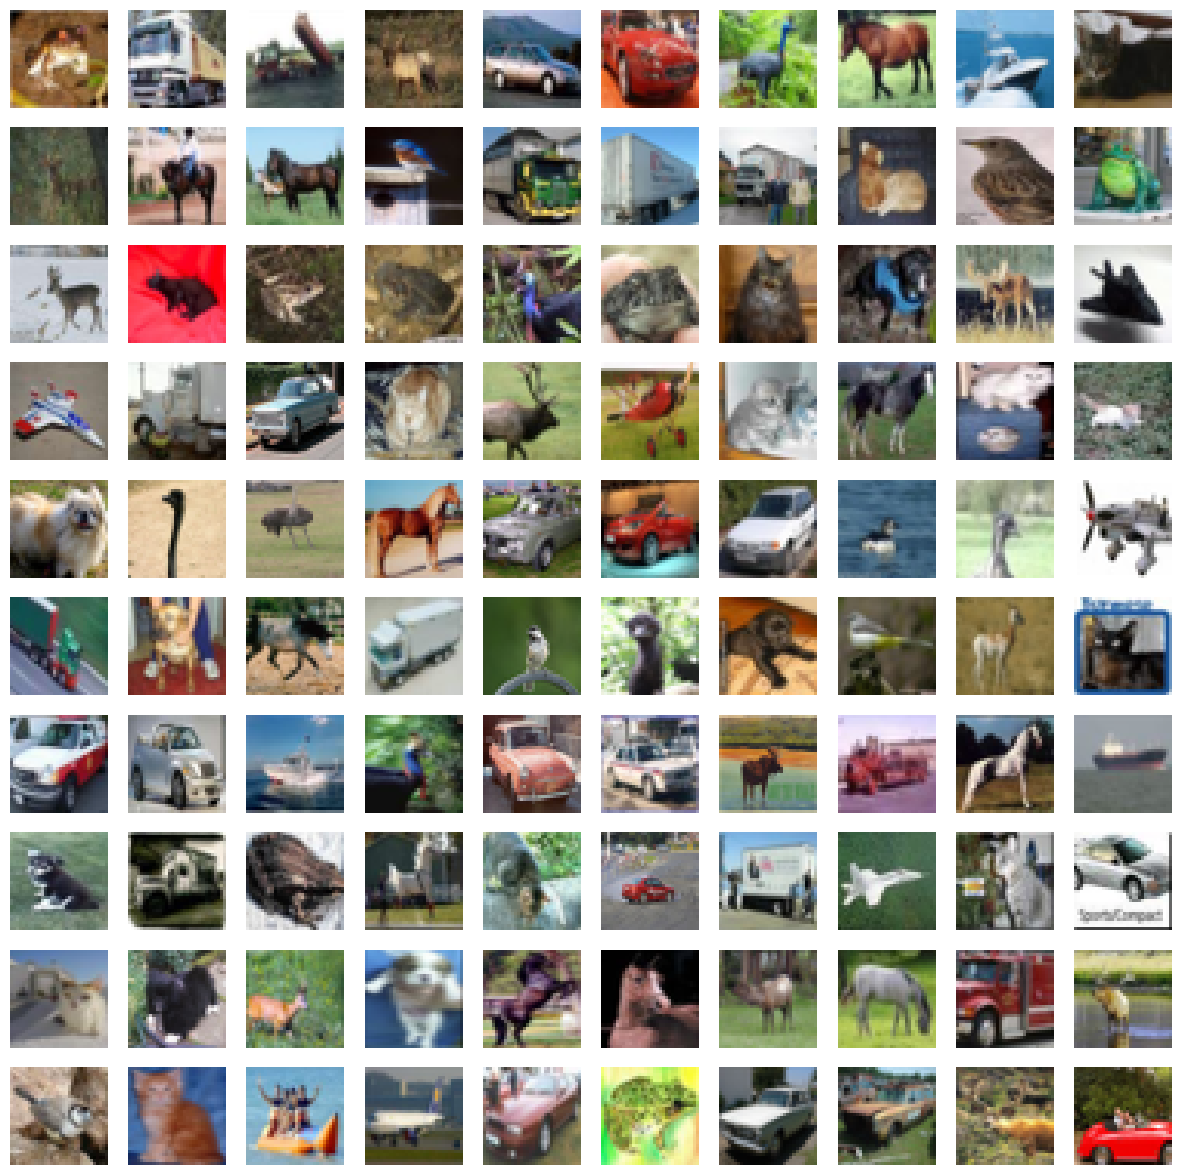

(50000, 32, 32, 3)
(10000, 32, 32, 3)
(50000, 10)
(10000, 10)


In [3]:
fig, axes = plt.subplots(ncols=10, nrows=10, figsize=(15, 15))
for i in range(10):
  for j in range(10):
    axes[i][j].imshow(x_train[(i * 10) + j], cmap=plt.get_cmap('gray'))
    axes[i][j].axis('off')
plt.show()

x_train = x_train.astype("float32") / 255
x_test = x_test.astype("float32") / 255

print(x_train.shape)
print(x_test.shape)

from tensorflow.keras.utils import to_categorical

y_train = to_categorical(y_train, num_classes=10)
y_test = to_categorical(y_test, num_classes=10)

print(y_train.shape)
print(y_test.shape)

## Define the following model

**For the convolutional front-end, start with a single convolutional layer with a small filter size (3,3) and a modest number of filters (32) followed by a max pooling layer. Use the input as (32,32,3). The filter maps can then be flattened to provide features to the classifier. Use a dense layer with 100 units before the classification layer (which is also a dense layer with softmax activation).**

In [4]:
from keras.backend import clear_session
clear_session()

In [5]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Input

model = Sequential()
model.add(Input(shape=(32, 32, 3)))
model.add(Conv2D(32, (3, 3), activation='relu', kernel_initializer='he_uniform'))
model.add(MaxPooling2D((2, 2)))
model.add(Flatten())
model.add(Dense(100, activation='relu', kernel_initializer='he_uniform'))
model.add(Dense(10, activation='softmax'))

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 30, 30, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 15, 15, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 7200)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 100)            │       720,100 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,010 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 722,006 (2.75 MB)

 Trainable params: 722,006 (2.75 MB)

 Non-trainable params: 0 (0.00 B)

*   Compile the model using categorical_crossentropy loss, SGD optimizer and use 'accuracy' as the metric.
*   Use the above defined model to train CIFAR-10 and train the model for 512 epochs with a batch size of 32.

In [6]:
# solution
model.compile(loss='categorical_crossentropy', optimizer='sgd', metrics=['accuracy'])
history_shallow = model.fit(x_train, y_train, epochs=50, batch_size=32, validation_split=0.1)


Epoch 1/50
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 18s 8ms/step - accuracy: 0.3531 - loss: 1.8077 - val_accuracy: 0.4118 - val_loss: 1.6192
Epoch 2/50
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.4838 - loss: 1.4513 - val_accuracy: 0.4780 - val_loss: 1.4801
Epoch 3/50
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.5384 - loss: 1.3063 - val_accuracy: 0.5580 - val_loss: 1.2649
Epoch 4/50
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.5710 - loss: 1.2232 - val_accuracy: 0.5362 - val_loss: 1.3192
Epoch 5/50
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.5952 - loss: 1.1587 - val_accuracy: 0.5984 - val_loss: 1.1766
Epoch 6/50
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.6145 - loss: 1.1066 - val_accuracy: 0.5246 - val_loss: 1.3324
Epoch 7/50
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.6323 - loss: 1.0540 - val_accuracy: 0.6096 - val_loss: 1.1248
Epoch 8/50
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.6511 - loss: 1.0088 -

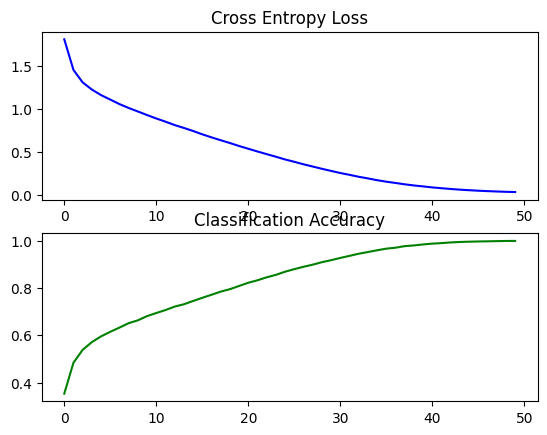

In [7]:
plt.subplot(211)
plt.title('Cross Entropy Loss')
plt.plot(history_shallow.history['loss'], color='blue', label='train')

plt.subplot(212)
plt.title('Classification Accuracy')
plt.plot(history_shallow.history['accuracy'], color='green', label='train')
plt.show()

### Model Passport - Shallow CNN

| Metadato | Detalle |
|---|---|
| **Model Name** | Shallow CNN (model) |
| **Dataset** | CIFAR-10 |
| **Training Sample Size** | 50,000 images |
| **Class Names** | 10 CIFAR-10 Classes |
| **Preprocessing Instructions** | Conversion to `float32` and division by `255.0` (normalization to $[0, 1]$) |
| **Optimizer & Loss** | SGD, Categorical Crossentropy |
| **Epochs / Batch Size** | 50 Epochs / 32 Batch Size |
| **Final Metrics** | Validation Accuracy: **~66.32%** |

In [49]:
import json

# Save weights for Shallow CNN (using Keras 3 expected .weights.h5 extension)
if 'model' in globals():
    model.save_weights('shallow_cnn_weights.weights.h5')
    print("Shallow CNN weights saved successfully.")

# Create and save passport
shallow_passport = {
    "model_name": "shallow_cnn",
    "dataset": "CIFAR-10",
    "sample_size": {"train": 50000, "test": 10000},
    "class_names": CLASS_NAMES if 'CLASS_NAMES' in globals() else [],
    "preprocessing_instructions": "Cast inputs to float32 and divide by 255.0",
    "training_history": {metric: [float(v) for v in values] for metric, values in history_shallow.history.items()} if 'history_shallow' in globals() else "No history"
}

with open('shallow_cnn_passport.json', 'w') as f:
    json.dump(shallow_passport, f, indent=4)
print("Shallow CNN passport saved to 'shallow_cnn_passport.json'")

Shallow CNN weights saved successfully.
Shallow CNN passport saved to 'shallow_cnn_passport.json'


## Defining Deeper Architectures: VGG Models

*   Define a deeper model architecture for CIFAR-10 dataset and train the new model for 512 epochs with a batch size of 32. We will use VGG model as the architecture.

**Stack two convolutional layers with 32 filters, each of 3 x 3. Use a max pooling layer and next flatten the output of the previous layer and add a dense layer with 128 units before the classification layer. For all the layers, use ReLU activation function. Use same padding for the layers to ensure that the height and width of each layer output matches the input**


In [22]:
from keras.backend import clear_session
clear_session()

In [25]:
# solution
deeper_model = Sequential()
deeper_model.add(Input(shape=(32, 32, 3)))
deeper_model.add(Conv2D(32, (3, 3), activation='relu', kernel_initializer='he_uniform', padding='same'))
deeper_model.add(Conv2D(32, (3, 3), activation='relu', kernel_initializer='he_uniform', padding='same'))
deeper_model.add(MaxPooling2D((2, 2)))
deeper_model.add(Flatten())
deeper_model.add(Dense(128, activation='relu', kernel_initializer='he_uniform'))
deeper_model.add(Dense(10, activation='softmax'))

deeper_model.summary()


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_2 (Conv2D)               │ (None, 32, 32, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 32, 32, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 8192)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │     1,048,704 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,060,138 (4.04 MB)

 Trainable params: 1,060,138 (4.04 MB)

 Non-trainable params: 0 (0.00 B)

*   Compile the model using categorical_crossentropy loss, SGD optimizer and use 'accuracy' as the metric.
*   Use the above defined model to train CIFAR-10 and train the model for 512 epochs with a batch size of 32.

In [26]:
# solution
deeper_model.compile(loss='categorical_crossentropy', optimizer='sgd', metrics=['accuracy'])
history_deeper = deeper_model.fit(x_train, y_train, epochs=50, batch_size=32, validation_split=0.1)

Epoch 1/50
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 11s 6ms/step - accuracy: 0.3880 - loss: 1.7171 - val_accuracy: 0.4258 - val_loss: 1.5319
Epoch 2/50
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.5206 - loss: 1.3492 - val_accuracy: 0.4816 - val_loss: 1.4490
Epoch 3/50
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 5s 4ms/step - accuracy: 0.5859 - loss: 1.1788 - val_accuracy: 0.5302 - val_loss: 1.3735
Epoch 4/50
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 5s 4ms/step - accuracy: 0.6300 - loss: 1.0613 - val_accuracy: 0.5480 - val_loss: 1.2717
Epoch 5/50
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 5s 4ms/step - accuracy: 0.6654 - loss: 0.9608 - val_accuracy: 0.6158 - val_loss: 1.0869
Epoch 6/50
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 5s 4ms/step - accuracy: 0.6953 - loss: 0.8731 - val_accuracy: 0.5658 - val_loss: 1.2851
Epoch 7/50
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.7224 - loss: 0.7968 - val_accuracy: 0.6386 - val_loss: 1.0434
Epoch 8/50
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 5s 4ms/step - accuracy: 0.7502 - loss: 0.7227 -

### Model Passport - Deeper VGG

| Metadato | Detalle |
|---|---|
| **Model Name** | Deeper VGG (deeper_model) |
| **Dataset** | CIFAR-10 |
| **Training Sample Size** | 50,000 images |
| **Class Names** | 10 CIFAR-10 Classes |
| **Preprocessing Instructions** | Conversion to `float32`, division by `255.0` and same-padding on Conv layers |
| **Optimizer & Loss** | SGD, Categorical Crossentropy |
| **Epochs / Batch Size** | 50 Epochs / 32 Batch Size |
| **Final Metrics** | Validation Accuracy: **~68.84%** |

In [50]:
import json

# Save weights for Deeper VGG (using Keras 3 expected .weights.h5 extension)
if 'deeper_model' in globals():
    deeper_model.save_weights('deeper_vgg_weights.weights.h5')
    print("Deeper VGG weights saved successfully.")

# Create and save passport
deeper_passport = {
    "model_name": "deeper_vgg",
    "dataset": "CIFAR-10",
    "sample_size": {"train": 50000, "test": 10000},
    "class_names": CLASS_NAMES if 'CLASS_NAMES' in globals() else [],
    "preprocessing_instructions": "Cast inputs to float32, divide by 255.0, padding='same'",
    "training_history": {metric: [float(v) for v in values] for metric, values in history_deeper.history.items()} if 'history_deeper' in globals() else "No history"
}

with open('deeper_vgg_passport.json', 'w') as f:
    json.dump(deeper_passport, f, indent=4)
print("Deeper VGG passport saved to 'deeper_vgg_passport.json'")

Deeper VGG weights saved successfully.
Deeper VGG passport saved to 'deeper_vgg_passport.json'


*   Compare the performance of both the models by plotting the loss and accuracy curves of both the training steps. Does the deeper model perform better?


In [28]:

print(history_deeper.history)

{'accuracy': [0.38795554637908936, 0.520622193813324, 0.5859110951423645, 0.6300222277641296, 0.6653777956962585, 0.6952666640281677, 0.7223777770996094, 0.7502444386482239, 0.7736444473266602, 0.8027777671813965, 0.8219777941703796, 0.8474222421646118, 0.8721110820770264, 0.8931333422660828, 0.9126222133636475, 0.9340888857841492, 0.9504666924476624, 0.966355562210083, 0.9775111079216003, 0.9874666929244995, 0.9929555654525757, 0.9964444637298584, 0.9983999729156494, 0.9990888833999634, 0.999488890171051, 0.9997333288192749, 0.9997333288192749, 0.9998000264167786, 0.9999555349349976, 0.999822199344635, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0], 'loss': [1.7170586585998535, 1.3492205142974854, 1.1787797212600708, 1.0612831115722656, 0.9608326554298401, 0.873062789440155, 0.7968268394470215, 0.7227288484573364, 0.6552093625068665, 0.5837612748146057, 0.5194521546363831, 0.4488523006439209, 0.38614001870155334, 0.3247545659542084,

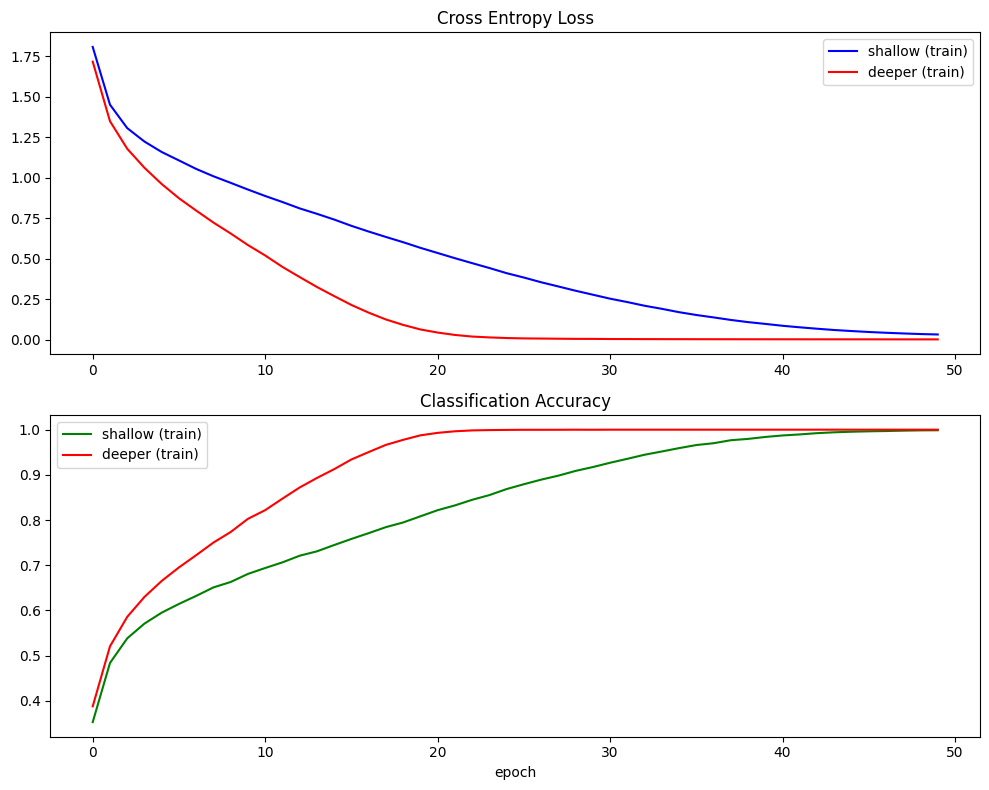

In [29]:
# solution
plt.figure(figsize=(10, 8))

plt.subplot(211)
plt.title('Cross Entropy Loss')
plt.plot(history_shallow.history['loss'], color='blue', label='shallow (train)')
plt.plot(history_deeper.history['loss'], color='red', label='deeper (train)')
plt.legend()

plt.subplot(212)
plt.title('Classification Accuracy')
plt.plot(history_shallow.history['accuracy'], color='green', label='shallow (train)')
plt.plot(history_deeper.history['accuracy'], color='red', label='deeper (train)')
plt.xlabel('epoch')
plt.legend()

plt.tight_layout()
plt.show()

Both models reach 100% training accuracy, so on the training set they look equally good. The VGG deeper model (two stacked 3×3 convolutions) learns faster: its training loss reaches ~0 around epoch 20, while the shallow model needs ~45–50 epochs. This is because the deeper model has more capacity and a larger receptive field. However, 100% training accuracy means both models have memorized the training data. The real comparison should be done with validation/test accuracy.

*   Use predict function to predict the output for the test split
*   Plot the confusion matrix for the new model and comment on the class confusions.


In [30]:
# solution
predictions = deeper_model.predict(x_test)

print(predictions.shape)
predictions = np.argmax(predictions, axis=1)
print(predictions.shape)
y_test = np.argmax(y_test, axis=1)
print(y_test.shape, predictions.shape)


313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step
(10000, 10)
(10000,)
(10000,) (10000,)


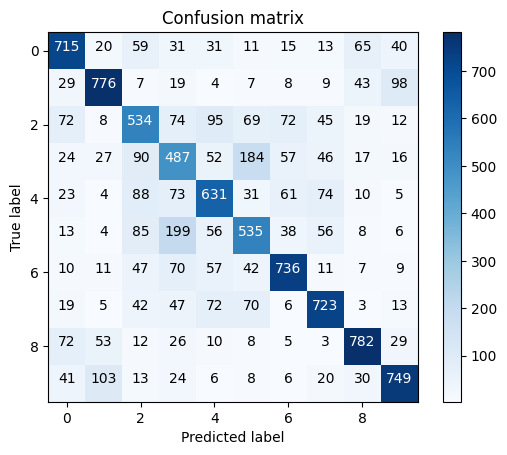

In [31]:
from sklearn.metrics import confusion_matrix
cm = confusion_matrix(y_test, predictions)
plt.imshow(cm, cmap=plt.cm.Blues)
# put numbers on the cells
thresh = cm.max() / 2.
for i, j in np.ndindex(cm.shape):
    plt.text(j, i, cm[i, j],
             horizontalalignment="center",
             color="white" if cm[i, j] > thresh else "black")
plt.title('Confusion matrix')
plt.ylabel('True label')
plt.xlabel('Predicted label')
plt.colorbar()
plt.show()

*    Print the test accuracy for the trained model.

In [32]:
# solution
y_test = to_categorical(y_test, num_classes=10)
test_loss, test_acc = model.evaluate(x_test, y_test)
print('Test accuracy:', test_acc)
print('Test loss:', test_loss)


313/313 ━━━━━━━━━━━━━━━━━━━━ 4s 13ms/step - accuracy: 0.6524 - loss: 1.7298
Test accuracy: 0.652400016784668
Test loss: 1.7298085689544678


## Define the complete VGG architecture.

**Stack two convolutional layers with 64 filters, each of 3 x 3 followed by max pooling layer. Stack two more convolutional layers with 128 filters, each of 3 x 3, followed by max pooling, follwed by two more convolutional layers with 256 filters, each of 3 x 3, followed by max pooling. Flatten the output of the previous layer and add a dense layer with 128 units before the classification layer. For all the layers, use ReLU activation function. Use same padding for the layers to ensure that the height and width of each layer output matches the input**

*   Change the size of input to 64 x 64.

In [33]:
from keras.backend import clear_session
clear_session()

In [34]:
# solution
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Resizing, Conv2D, MaxPooling2D, Flatten, Dense

vgg_model = Sequential(name="vgg_complete")

vgg_model.add(Input(shape=(32, 32, 3)))
vgg_model.add(Resizing(64, 64, name="resize_64"))

# Block 1: 2 x Conv(64, 3x3) + MaxPool  -> 32x32x64
vgg_model.add(Conv2D(64, (3, 3), activation='relu', kernel_initializer='he_uniform', padding='same'))
vgg_model.add(Conv2D(64, (3, 3), activation='relu', kernel_initializer='he_uniform', padding='same'))
vgg_model.add(MaxPooling2D((2, 2)))

# Block 2: 2 x Conv(128, 3x3) + MaxPool -> 16x16x128
vgg_model.add(Conv2D(128, (3, 3), activation='relu', kernel_initializer='he_uniform', padding='same'))
vgg_model.add(Conv2D(128, (3, 3), activation='relu', kernel_initializer='he_uniform', padding='same'))
vgg_model.add(MaxPooling2D((2, 2)))

# Block 3: 2 x Conv(256, 3x3) + MaxPool -> 8x8x256
vgg_model.add(Conv2D(256, (3, 3), activation='relu', kernel_initializer='he_uniform', padding='same'))
vgg_model.add(Conv2D(256, (3, 3), activation='relu', kernel_initializer='he_uniform', padding='same'))
vgg_model.add(MaxPooling2D((2, 2)))

# Classifier
vgg_model.add(Flatten())                                                         # 8*8*256 = 16384
vgg_model.add(Dense(128, activation='relu', kernel_initializer='he_uniform'))
vgg_model.add(Dense(10, activation='softmax'))

vgg_model.summary()


Model: "vgg_complete"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ resize_64 (Resizing)            │ (None, 64, 64, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 64, 64, 64)     │         1,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 64, 64, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 32, 32, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 32, 32, 128)    │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 16, 16, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 16, 16, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 8, 8, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 16384)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     2,097,280 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,243,978 (12.37 MB)

 Trainable params: 3,243,978 (12.37 MB)

 Non-trainable params: 0 (0.00 B)

*   Compile the model using categorical_crossentropy loss, SGD optimizer and use 'accuracy' as the metric.
*   Use the above defined model to train CIFAR-10 and train the model for 100 epochs with a batch size of 32.
*   Predict the output for the test split and plot the confusion matrix for the new model and comment on the class confusions.

Epoch 1/100
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 66s 38ms/step - accuracy: 0.4005 - loss: 1.6634 - val_accuracy: 0.3898 - val_loss: 1.6428
Epoch 2/100
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 38s 27ms/step - accuracy: 0.5744 - loss: 1.2023 - val_accuracy: 0.6320 - val_loss: 1.0520
Epoch 3/100
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 39s 27ms/step - accuracy: 0.6620 - loss: 0.9650 - val_accuracy: 0.6870 - val_loss: 0.9120
Epoch 4/100
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 37s 27ms/step - accuracy: 0.7278 - loss: 0.7859 - val_accuracy: 0.6290 - val_loss: 1.1054
Epoch 5/100
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 39s 27ms/step - accuracy: 0.7786 - loss: 0.6336 - val_accuracy: 0.7134 - val_loss: 0.8548
Epoch 6/100
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 38s 27ms/step - accuracy: 0.8315 - loss: 0.4872 - val_accuracy: 0.6914 - val_loss: 0.9479
Epoch 7/100
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 37s 27ms/step - accuracy: 0.8788 - loss: 0.3461 - val_accuracy: 0.6586 - val_loss: 1.1582
Epoch 8/100
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 37s 27ms/step - accuracy: 

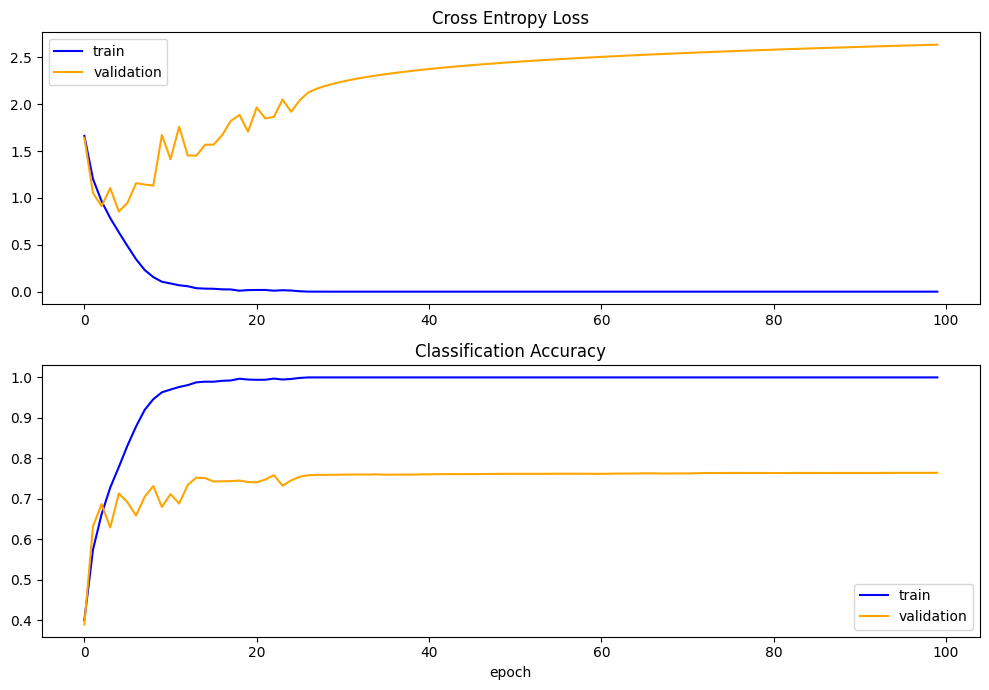

313/313 ━━━━━━━━━━━━━━━━━━━━ 6s 19ms/step
Test accuracy: 0.7412


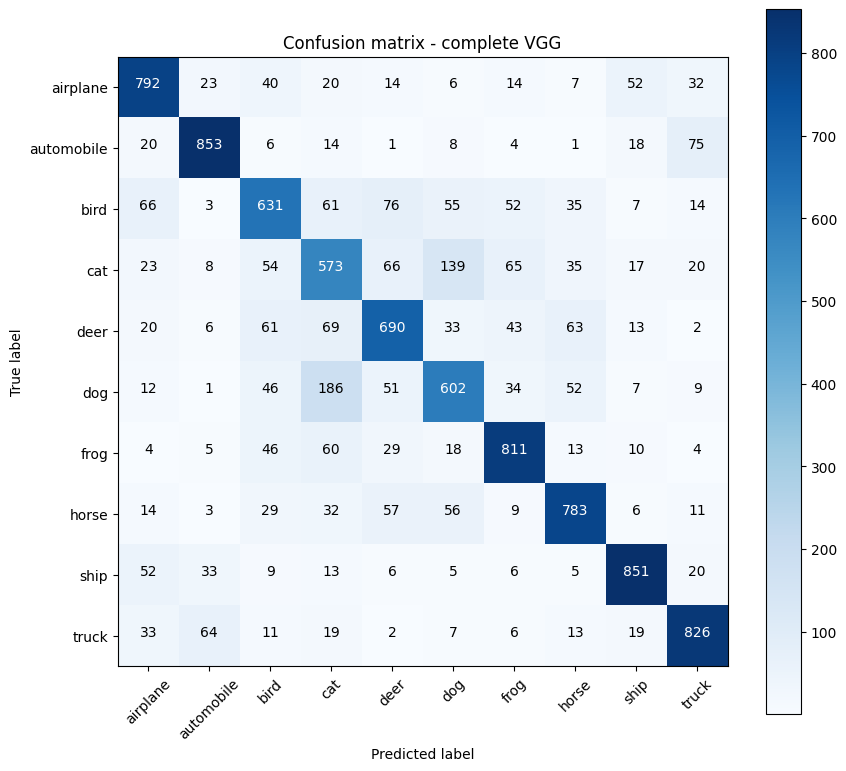

Most frequent confusions (true -> predicted):
         dog -> cat       : 186
         cat -> dog       : 139
        bird -> deer      : 76
  automobile -> truck     : 75
        deer -> cat       : 69
         cat -> deer      : 66


In [35]:
from sklearn.metrics import confusion_matrix

CLASS_NAMES = ['airplane', 'automobile', 'bird', 'cat', 'deer',
               'dog', 'frog', 'horse', 'ship', 'truck']

# 1. Compile: categorical cross-entropy, SGD, accuracy
vgg_model.compile(loss='categorical_crossentropy', optimizer='sgd', metrics=['accuracy'])

# 2. Train for 100 epochs, batch size 32
history_vgg = vgg_model.fit(x_train, y_train, epochs=100, batch_size=32, validation_split=0.1)

# training curves (train and validation)
plt.figure(figsize=(10, 7))
plt.subplot(211)
plt.title('Cross Entropy Loss')
plt.plot(history_vgg.history['loss'], color='blue', label='train')
plt.plot(history_vgg.history['val_loss'], color='orange', label='validation')
plt.legend()
plt.subplot(212)
plt.title('Classification Accuracy')
plt.plot(history_vgg.history['accuracy'], color='blue', label='train')
plt.plot(history_vgg.history['val_accuracy'], color='orange', label='validation')
plt.xlabel('epoch')
plt.legend()
plt.tight_layout()
plt.show()

# 3. Predict the test split
# y_test may be one-hot or integer labels depending on which earlier cells were run
y_true = np.argmax(y_test, axis=1) if y_test.ndim > 1 else y_test.ravel()
y_pred = np.argmax(vgg_model.predict(x_test), axis=1)
print('Test accuracy:', np.mean(y_pred == y_true))

# confusion matrix
cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(9, 8))
plt.imshow(cm, cmap=plt.cm.Blues)
thresh = cm.max() / 2.
for i, j in np.ndindex(cm.shape):
    plt.text(j, i, cm[i, j], horizontalalignment="center",
             color="white" if cm[i, j] > thresh else "black")
plt.xticks(range(10), CLASS_NAMES, rotation=45)
plt.yticks(range(10), CLASS_NAMES)
plt.title('Confusion matrix - complete VGG')
plt.ylabel('True label')
plt.xlabel('Predicted label')
plt.colorbar()
plt.tight_layout()
plt.show()

# most frequent confusions (to help with the comment)
off_diag = [(cm[i, j], CLASS_NAMES[i], CLASS_NAMES[j]) for i in range(10) for j in range(10) if i != j]
print('Most frequent confusions (true -> predicted):')
for n, t, p in sorted(off_diag, reverse=True)[:6]:
    print(f'  {t:>10s} -> {p:<10s}: {n}')



# Understanding deep networks

*   What is the use of activation functions in network? Why is it needed?
    
    Activation functions introduce non-linearity into the network. Without them, each layer only multiplies its inputs by weights and adds a bias, and stacking these linear layers still gives a linear function, so a deep network would be equivalent to a single layer and could only learn linear decision boundaries. Adding a non-linear function such as ReLU after each convolutional layer prevents the layers from collapsing into one, so the network can learn complex patterns and build hierarchical features. An activation in the output layer also turns the output into the format the task needs, such as probabilities.

*   We have used softmax activation function in the exercise. There are other activation functions available too. What is the difference between sigmoid activation and softmax activation?
    
    Sigmoid is applied to each output independently and maps it to a value between 0 and 1, but the outputs do not have to sum to 1. That makes it suitable for binary classification or multi-label problems, where an example can belong to several classes at once. Softmax is applied to the whole output vector and turns it into a probability distribution that sums to 1, so the classes compete with each other. That makes it suitable for multi-class problems where each example belongs to exactly one class. With two classes, softmax and sigmoid are equivalent.

*   What is the difference between categorical crossentropy and binary crossentropy loss?
    
    Categorical crossentropy is used for multi-class classification with mutually exclusive classes, together with softmax and one-hot labels. Binary crossentropy is used for binary or multi-label classification, together with sigmoid, penalizing both false positives and false negatives. Both measure the negative log-probability of the true outcome, and binary crossentropy is the two-class case of categorical crossentropy.

# Transfer Learning

It is not always necessary to train models from scratch. We can use the knowledge of networks trained on other tasks to learn the task at hand. In this exercise, we will explore the use of pre-trained weights and train on the CIFAR-10 dataset.

*   Create a base imagenet pretrained InceptionV3 model.
    *    Hint: Use tf.keras.applications to create the model
    *    Pay attention to the include_top parameter.
*    Add a global average pooling layer, followed by a fully-connected layer with 1024 neurons and then the classification layer.
*   Train the model by freezing the base model. Train only the newly added layers.
    *    Hint: Every layer has an attribute called 'trainable'
*   Compile the model and train the model for a few epochs only.

In [58]:
from keras.backend import clear_session
clear_session()

In [59]:
# solution
from keras.applications import InceptionV3
from tensorflow.keras.optimizers import Adam
from keras.layers import Dense, GlobalAveragePooling2D
from keras.models import Model

inception_model = InceptionV3(
    include_top=False,
    weights="imagenet",
    input_tensor=None,
    input_shape=None,
    pooling=None,
    classes=1000,
    classifier_activation="softmax",
    name="inception_v3",
)

# freeze the base model
for layer in inception_model.layers:
    layer.trainable = False

x = inception_model.output
x = GlobalAveragePooling2D(name="global_avg_pool")(x)
x = Dense(1024, activation='relu', name="custom_dense")(x)
predictions = Dense(10, activation='softmax', name="predictions")(x)

model = Model(inputs=inception_model.input, outputs=predictions)

learning_rate = 0.001
model.compile(optimizer=Adam(learning_rate=learning_rate), loss='categorical_crossentropy', metrics=['accuracy'])
# model.summary()

In [60]:
# resize all images in x_train to 64x64, the shape of x_train is (50000, 32, 32, 3)
from skimage import transform
x_train_small = np.array([transform.resize(img, (128, 128, 3), preserve_range=True, anti_aliasing=True) for img in x_train[:1000]])

In [61]:
# solution
y_train_small = y_train[:1000]
model.fit(x_train_small, y_train_small, epochs=10, batch_size=32, validation_split=0.1)

Epoch 1/10
29/29 ━━━━━━━━━━━━━━━━━━━━ 29s 627ms/step - accuracy: 0.3289 - loss: 4.4095 - val_accuracy: 0.5100 - val_loss: 1.3325
Epoch 2/10
29/29 ━━━━━━━━━━━━━━━━━━━━ 1s 32ms/step - accuracy: 0.7411 - loss: 0.8347 - val_accuracy: 0.6600 - val_loss: 0.9991
Epoch 3/10
29/29 ━━━━━━━━━━━━━━━━━━━━ 1s 29ms/step - accuracy: 0.8522 - loss: 0.4727 - val_accuracy: 0.6400 - val_loss: 1.0351
Epoch 4/10
29/29 ━━━━━━━━━━━━━━━━━━━━ 1s 29ms/step - accuracy: 0.9322 - loss: 0.2689 - val_accuracy: 0.7000 - val_loss: 0.8576
Epoch 5/10
29/29 ━━━━━━━━━━━━━━━━━━━━ 1s 29ms/step - accuracy: 0.9711 - loss: 0.1583 - val_accuracy: 0.6500 - val_loss: 1.0127
Epoch 6/10
29/29 ━━━━━━━━━━━━━━━━━━━━ 1s 29ms/step - accuracy: 0.9900 - loss: 0.0893 - val_accuracy: 0.7000 - val_loss: 0.9810
Epoch 7/10
29/29 ━━━━━━━━━━━━━━━━━━━━ 1s 29ms/step - accuracy: 0.9922 - loss: 0.0546 - val_accuracy: 0.7000 - val_loss: 0.8910
Epoch 8/10
29/29 ━━━━━━━━━━━━━━━━━━━━ 1s 29ms/step - accuracy: 1.0000 - loss: 0.0273 - val_accuracy: 0.6600 -

*    Freeze the bottom layers and unfreeze the base layers.
*    Compile and train the classifier with a very low learning rate (0.0001)

In [62]:
for layer in inception_model.layers:
  layer.trainable = True
for layer in model.layers:
  if layer.name in ['custom_dense', 'predictions']:
    layer.trainable = False
model.compile(optimizer=Adam(learning_rate=0.0001), loss='categorical_crossentropy', metrics=['accuracy'])
model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, None,      │          0 │ -                 │
│ (InputLayer)        │ None, 3)          │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d (Conv2D)     │ (None, None,      │        864 │ input_layer[0][0] │
│                     │ None, 32)         │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalization │ (None, None,      │         96 │ conv2d[0][0]      │
│ (BatchNormalizatio… │ None, 32)         │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation          │ (None, None,      │          0 │ batch_normalizat… │
│ (Activation)        │ None, 32)         │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_1 (Conv2D)   │ (None, None,      │      9,216 │ activation[0][0]  │
│                     │ None, 32)         │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, None,      │         96 │ conv2d_1[0][0]    │
│ (BatchNormalizatio… │ None, 32)         │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_1        │ (None, None,      │          0 │ batch_normalizat… │
│ (Activation)        │ None, 32)         │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_2 (Conv2D)   │ (None, None,      │     18,432 │ activation_1[0][… │
│                     │ None, 64)         │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, None,      │        192 │ conv2d_2[0][0]    │
│ (BatchNormalizatio… │ None, 64)         │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_2        │ (None, None,      │          0 │ batch_normalizat… │
│ (Activation)        │ None, 64)         │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d       │ (None, None,      │          0 │ activation_2[0][… │
│ (MaxPooling2D)      │ None, 64)         │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_3 (Conv2D)   │ (None, None,      │      5,120 │ max_pooling2d[0]… │
│                     │ None, 80)         │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, None,      │        240 │ conv2d_3[0][0]    │
│ (BatchNormalizatio… │ None, 80)         │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_3        │ (None, None,      │          0 │ batch_normalizat… │
│ (Activation)        │ None, 80)         │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_4 (Conv2D)   │ (None, None,      │    138,240 │ activation_3[0][… │
│                     │ None, 192)        │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, None,      │        576 │ conv2d_4[0][0]    │
│ (BatchNormalizatio… │ None, 192)        │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_4        │ (None, None,      │          0 │ batch_normalizat

 Total params: 23,911,210 (91.21 MB)

 Trainable params: 21,768,352 (83.04 MB)

 Non-trainable params: 2,142,858 (8.17 MB)

In [63]:
import json

# 1. Save weights for the InceptionV3 Transfer Learning model
if 'model' in globals():
    model.save_weights('transfer_learning_inception_weights.weights.h5')
    print("Transfer Learning model weights saved successfully.")

    # 2. Save the InceptionV3 Transfer Learning architecture to a native JSON file
    transfer_architecture_json = model.to_json()
    with open('transfer_learning_inception_architecture.json', 'w') as f:
        f.write(transfer_architecture_json)
    print("Transfer Learning architecture successfully saved to 'transfer_learning_inception_architecture.json'")

# 3. Create and save passport for the Transfer Learning model
transfer_passport = {
    "model_name": "transfer_learning_inceptionv3",
    "dataset": "CIFAR-10",
    "sample_size": {"train": 1000, "test": 10000},
    "class_names": CLASS_NAMES if 'CLASS_NAMES' in globals() else [],
    "preprocessing_instructions": "Resize inputs to 128x128x3 using skimage.transform.resize",
    "optimizer_and_loss": "Adam (lr=0.001 then 0.0001 fine-tuning), Categorical Crossentropy"
}

with open('transfer_learning_inception_passport.json', 'w') as f:
    json.dump(transfer_passport, f, indent=4)
print("Transfer Learning passport successfully saved to 'transfer_learning_inception_passport.json'")

Transfer Learning model weights saved successfully.
Transfer Learning architecture successfully saved to 'transfer_learning_inception_architecture.json'
Transfer Learning passport successfully saved to 'transfer_learning_inception_passport.json'


*    When do we train models from scratch? What are the potential issues in training models from scratch?

*When to train from scratch:*
* When there is a **large labelled dataset** for the task, so the network can learn good features by itself.
* When the data is **very different** from the data the available pretrained models saw: medical scans, satellite or multispectral images, depth maps, spectrograms, or inputs with a different number of channels.
* When a **custom or very small architecture** is needed (for example for an embedded device) and no pretrained weights exist for it.

*Potential issues:*
* It needs **a lot of data**. With little data the network memorises the training set (overfitting), as our shallow and deeper models did (100% train accuracy, much lower validation accuracy).
* It needs **a lot of compute and time**, because every weight starts from random values and many epochs are needed.
* Training is more **sensitive to the choices** of initialisation, learning rate and regularisation, and it can converge slowly or become unstable.

*    Why do we use pre-trained weights?
 A network trained on a large dataset such as ImageNet has already learned features that are useful for most images. The first layers detect edges, colours and textures, and the middle layers detect parts and shapes. Reusing them means we need **much less data and training time**, and we usually get **better accuracy** when the target dataset is small. They also act as a form of regularisation: the model starts from sensible features instead of fitting noise.

*    What is the difference between using random initialization and using weights from a pre-trained model?


| | Random initialisation | Pre-trained weights |
|---|---|---|
| Starting point | weights carry no knowledge; the initial loss is high | weights already encode general visual features |
| What has to be learned | everything, from edges to classes | only how to adapt the features to the new classes |
| Data and time needed | a lot | much less; converges in a few epochs |
| Risk with small data | strong overfitting | lower; the features are already general |
| Constraints | none: any architecture, input size or channels | same architecture, preprocessing and RGB input as the original training; features are biased towards the source domain (ImageNet) |

### Set 8.2 Load pretrained model and use

=== LOADED MODEL PASSPORT METADATA ===
MODEL_NAME: transfer_learning_inceptionv3
DATASET: CIFAR-10
SAMPLE_SIZE: {'train': 1000, 'test': 10000}
CLASS_NAMES: ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']
PREPROCESSING_INSTRUCTIONS: Resize inputs to 128x128x3 using skimage.transform.resize
OPTIMIZER_AND_LOSS: Adam (lr=0.001 then 0.0001 fine-tuning), Categorical Crossentropy

=== Reconstructing model dynamically from Keras JSON file ===
Model architecture successfully reconstructed from JSON!


/usr/local/lib/python3.13/dist-packages/keras/src/saving/saving_lib.py:797: UserWarning: Skipping variable loading for optimizer 'adam', because it has 378 variables whereas the saved optimizer has 2 variables. 
  saveable.load_own_variables(weights_store.get(inner_path))


Weights loaded successfully onto the reconstructed InceptionV3 architecture.


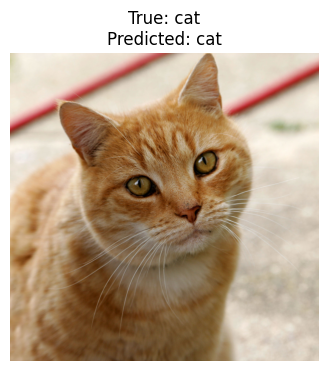

In [66]:
import json
import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras.models import model_from_json
from skimage.transform import resize
from tensorflow.keras.preprocessing.image import load_img, img_to_array

try:
    with open('transfer_learning_inception_passport.json', 'r') as f:
        passport_data = json.load(f)
    print("=== LOADED MODEL PASSPORT METADATA ===")
    for key, val in passport_data.items():
        print(f"{key.upper()}: {val}")
except FileNotFoundError:
    print("File 'transfer_learning_inception_passport.json' was not found.")

print("\n=== Reconstructing model dynamically from Keras JSON file ===")
try:
    with open('transfer_learning_inception_architecture.json', 'r') as f:
        loaded_architecture_json = f.read()

    loaded_model = model_from_json(loaded_architecture_json)
    print("Model architecture successfully reconstructed from JSON!")

    loaded_model.load_weights('transfer_learning_inception_weights.weights.h5')
    print("Weights loaded successfully onto the reconstructed InceptionV3 architecture.")
except Exception as e:
    print("Error during model reconstruction or loading weights:", e)

try:

    user_image_raw = img_to_array(load_img('cat.jpg')) / 255.0

    test_image_resized = resize(user_image_raw, (128, 128, 3), preserve_range=True, anti_aliasing=True)

    prediction = loaded_model.predict(np.expand_dims(test_image_resized, axis=0), verbose=0)
    predicted_label_idx = np.argmax(prediction)

    CLASS_NAMES = ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']
    pred_name = CLASS_NAMES[predicted_label_idx]

    plt.figure(figsize=(4, 4))
    plt.imshow(user_image_raw)  # Mostrar tu imagen original cargada
    plt.title(f"True: cat\nPredicted: {pred_name}", fontsize=12)
    plt.axis('off')
    plt.show()
except Exception as e:
    print("Error loading or predicting the user image 'cat.jpg':", e)

# Extracting features from Deep Networks

It is quite possible to extract features (similar to SIFT or ORB) from different layers of deep network.

*   Load ResNet50 model with imagenet weights and check the summary of the model
*   Create a model to extract features from the 'avg_pool' layer.
*   Extract features from the layer for all the train images.
*   Use the extracted features to train a SVM classifier.
    *    Use GridSearchCV and SVC to perform the classification

In [41]:
# solution
from tensorflow.keras.applications import ResNet50
from tensorflow.keras import Model

model = ResNet50()
model.summary()

102967424/102967424 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step


Model: "resnet50"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_1       │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_pad           │ (None, 230, 230,  │          0 │ input_layer_1[0]… │
│ (ZeroPadding2D)     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_conv (Conv2D) │ (None, 112, 112,  │      9,472 │ conv1_pad[0][0]   │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_bn            │ (None, 112, 112,  │        256 │ conv1_conv[0][0]  │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_relu          │ (None, 112, 112,  │          0 │ conv1_bn[0][0]    │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ pool1_pad           │ (None, 114, 114,  │          0 │ conv1_relu[0][0]  │
│ (ZeroPadding2D)     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ pool1_pool          │ (None, 56, 56,    │          0 │ pool1_pad[0][0]   │
│ (MaxPooling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_1_conv │ (None, 56, 56,    │      4,160 │ pool1_pool[0][0]  │
│ (Conv2D)            │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_1_bn   │ (None, 56, 56,    │        256 │ conv2_block1_1_c… │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_1_relu │ (None, 56, 56,    │          0 │ conv2_block1_1_b… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_2_conv │ (None, 56, 56,    │     36,928 │ conv2_block1_1_r… │
│ (Conv2D)            │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_2_bn   │ (None, 56, 56,    │        256 │ conv2_block1_2_c… │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_2_relu │ (None, 56, 56,    │          0 │ conv2_block1_2_b… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_0_conv │ (None, 56, 56,    │     16,640 │ pool1_pool[0][0]  │
│ (Conv2D)            │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_3_conv │ (None, 56, 56,    │     16,640 │ conv2_block1_2_r… │
│ (Conv2D)            │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_0_bn   │ (None, 56, 56,    │      1,024 │ conv2_block1_0_c… │
│ (BatchNormalizatio… │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_3_bn   │ (None, 56, 56,    │      1,024 │ conv2_block1_3_c

 Total params: 25,636,712 (97.80 MB)

 Trainable params: 25,583,592 (97.59 MB)

 Non-trainable params: 53,120 (207.50 KB)

*    Evaluate the trained SVM model using the test set
*    Calculate the accuracy score and confusion matrix

In [42]:
# solution
from skimage import transform

extract = Model(model.inputs, model.get_layer('avg_pool').output)

dl_feature_descriptors = []

N = 50
# get N examples per class
x_train_stratified = np.empty((10*N,)+x_train[0].shape)
y_train_stratified = np.empty((10*N,)+y_train[0].shape)
for cl in range(10):
  x_train_stratified[cl*N:(cl+1)*N] = x_train[np.where(np.argmax(y_train, axis=1) == cl)[0][:N]]
  y_train_stratified[cl*N:(cl+1)*N] = y_train[np.where(np.argmax(y_train, axis=1) == cl)[0][:N]]
print(np.unique(np.argmax(y_train_stratified, axis=1), return_counts=True))

# resize to 224x224x3
x_train_stratified = np.array([
  transform.resize(img, (224, 224, 3), preserve_range=True, anti_aliasing=True)
  for img in x_train_stratified
  ])
batch_size = 32
for i in range(0, len(x_train_stratified), batch_size):
  example = x_train_stratified[i:i+batch_size]
  desc = extract.predict(example)
  dl_feature_descriptors.append(desc)

dl_feature_descriptors = np.concatenate(dl_feature_descriptors, axis=0)
print(dl_feature_descriptors.shape)

(array([0, 1, 2, 3, 4, 5, 6, 7, 8, 9]), array([50, 50, 50, 50, 50, 50, 50, 50, 50, 50]))
1/1 ━━━━━━━━━━━━━━━━━━━━ 19s 19s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 146ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 138ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 132ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 118ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 116ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 135ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 132ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 131ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 152ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 136ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 131ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 128ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 138ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 144ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 14s 14s/step
(500, 2048)


Starting GridSearchCV with SVC on extracted features...
Fitting 3 folds for each of 12 candidates, totalling 36 fits
Best parameters found: {'C': 10, 'gamma': 'scale', 'kernel': 'linear'}

Test Accuracy of SVM: 0.4300


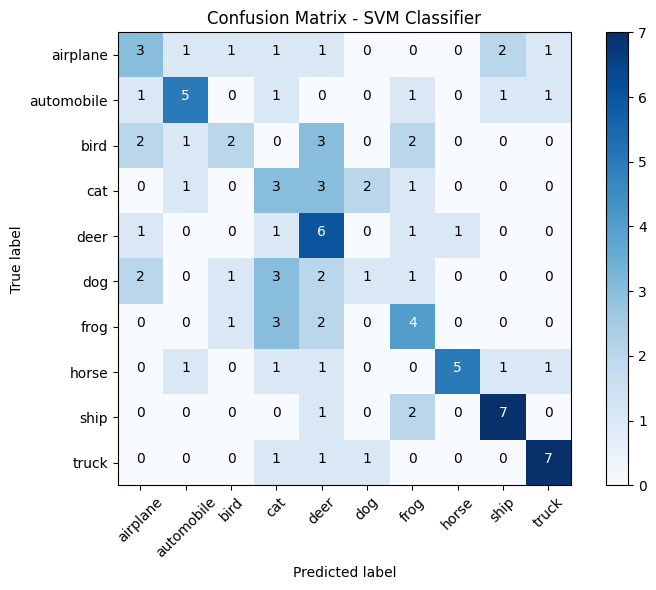

In [43]:
from sklearn.model_selection import GridSearchCV
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, confusion_matrix
import numpy as np
import matplotlib.pyplot as plt
from skimage import transform

# 1. Prepare training labels (integer classes)
y_train_labels = np.argmax(y_train_stratified, axis=1)

# 2. Set up GridSearchCV with SVC
param_grid = {
    'C': [0.1, 1, 10],
    'gamma': ['scale', 'auto'],
    'kernel': ['rbf', 'linear']
}

print("Starting GridSearchCV with SVC on extracted features...")
grid_search = GridSearchCV(SVC(), param_grid, cv=3, verbose=1)
grid_search.fit(dl_feature_descriptors, y_train_labels)

print("Best parameters found:", grid_search.best_params_)
best_svm = grid_search.best_estimator_

# 3. Stratify and prepare a test set to evaluate (N=10 examples per class for efficiency)
N_test = 10
x_test_stratified = np.empty((10 * N_test,) + x_test[0].shape)
y_test_stratified = np.empty((10 * N_test,) + y_test[0].shape)

for cl in range(10):
    indices = np.where(np.argmax(y_test, axis=1) == cl)[0][:N_test]
    x_test_stratified[cl * N_test:(cl + 1) * N_test] = x_test[indices]
    y_test_stratified[cl * N_test:(cl + 1) * N_test] = y_test[indices]

# Resize test set images
x_test_stratified_resized = np.array([
    transform.resize(img, (224, 224, 3), preserve_range=True, anti_aliasing=True)
    for img in x_test_stratified
])

# Extract features from test set
test_features = []
batch_size = 32
for i in range(0, len(x_test_stratified_resized), batch_size):
    batch = x_test_stratified_resized[i:i + batch_size]
    desc_test = extract.predict(batch, verbose=0)
    test_features.append(desc_test)

test_features = np.concatenate(test_features, axis=0)
y_test_labels = np.argmax(y_test_stratified, axis=1)

# 4. Predict and Evaluate
y_pred = best_svm.predict(test_features)
accuracy = accuracy_score(y_test_labels, y_pred)
print(f"\nTest Accuracy of SVM: {accuracy:.4f}")

# 5. Calculate and Plot Confusion Matrix
cm_svm = confusion_matrix(y_test_labels, y_pred)

plt.figure(figsize=(8, 6))
plt.imshow(cm_svm, cmap=plt.cm.Blues)
thresh = cm_svm.max() / 2.
for i, j in np.ndindex(cm_svm.shape):
    plt.text(j, i, cm_svm[i, j],
             horizontalalignment="center",
             color="white" if cm_svm[i, j] > thresh else "black")

plt.title('Confusion Matrix - SVM Classifier')
plt.ylabel('True label')
plt.xlabel('Predicted label')
plt.xticks(range(10), CLASS_NAMES, rotation=45)
plt.yticks(range(10), CLASS_NAMES)
plt.colorbar()
plt.tight_layout()
plt.show()

# Feature Visualizations

In order to visualize the features of a higher dimension data, t-SNE is used. t-SNE converts the affinities of the data points to probabilities. It recreates the probability distribution in a low-dimensional space. It is very helpful in visualizing features of different layers in a neural network.

You can find more information about t-SNE [here](https://scikit-learn.org/stable/modules/manifold.html#t-distributed-stochastic-neighbor-embedding-t-sne)

*    Use TSNE to visualize the features extracted in the previous exercise.
    *    Hint: TSNE function is available in the *sklearn.manifold* package.

/usr/local/lib/python3.13/dist-packages/sklearn/manifold/_t_sne.py:1164: FutureWarning: 'n_iter' was renamed to 'max_iter' in version 1.5 and will be removed in 1.7.
  warnings.warn(


[t-SNE] Computing 121 nearest neighbors...
[t-SNE] Indexed 500 samples in 0.001s...
[t-SNE] Computed neighbors for 500 samples in 0.075s...
[t-SNE] Computed conditional probabilities for sample 500 / 500
[t-SNE] Mean sigma: 0.148360
[t-SNE] KL divergence after 250 iterations with early exaggeration: 55.182865
[t-SNE] KL divergence after 300 iterations: 0.806347


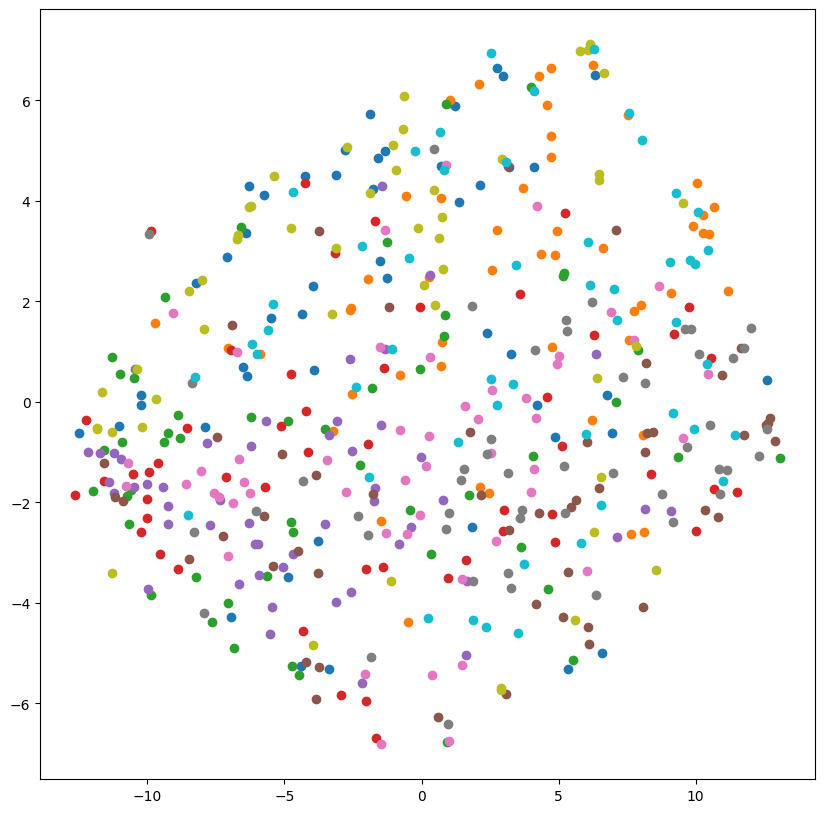

In [44]:
# solution
from sklearn.manifold import TSNE

tsne = TSNE(n_components=2, verbose=1, perplexity=40, n_iter=300)
tsne_results = tsne.fit_transform(dl_feature_descriptors)

plt.figure(figsize=(10, 10))
for cl in range(10):
  plt.scatter(tsne_results[np.where(np.argmax(y_train_stratified, axis=1) == cl)][:, 0],
              tsne_results[np.where(np.argmax(y_train_stratified, axis=1) == cl)][:, 1],
              label=cl)
plt.show()


Computing UMAP projection...


/usr/local/lib/python3.13/dist-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


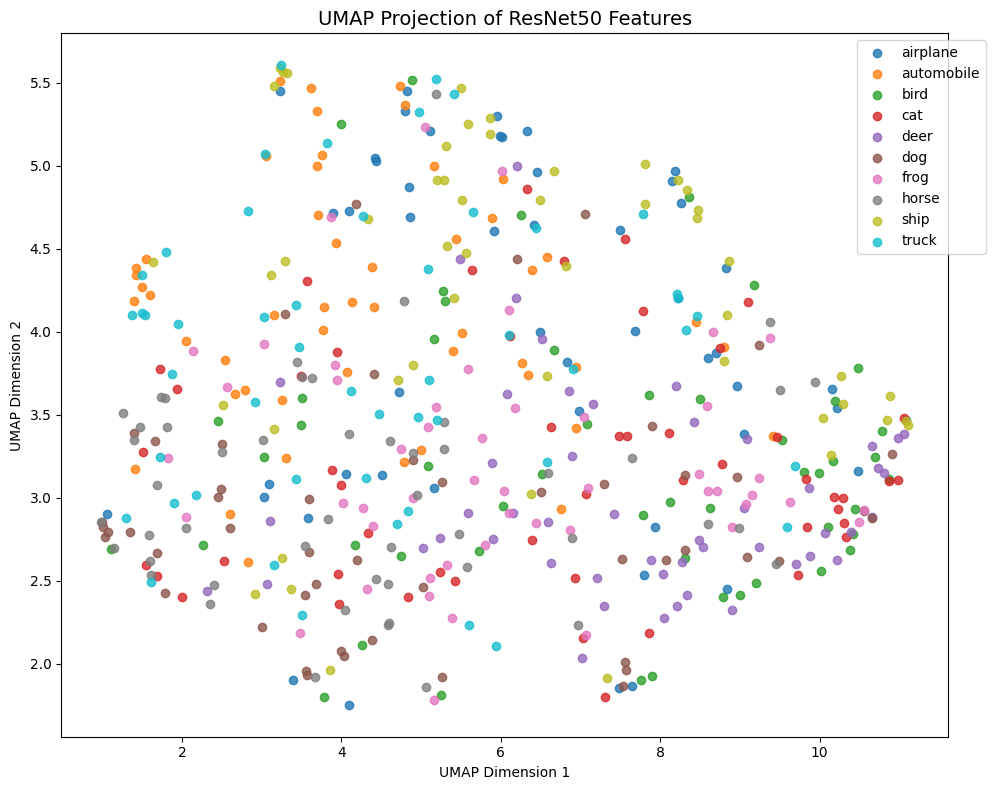

In [47]:
import sys
try:
    import umap
except ImportError:
    !pip install -q umap-learn
    import umap

import matplotlib.pyplot as plt
import numpy as np

# 1. Prepare labels for coloring
y_train_labels = np.argmax(y_train_stratified, axis=1)

# 2. Compute UMAP Projection
print("Computing UMAP projection...")
umap_reducer = umap.UMAP(n_neighbors=15, min_dist=0.1, n_components=2, random_state=42)
umap_features = umap_reducer.fit_transform(dl_feature_descriptors)

# 3. Plot UMAP
fig, ax = plt.subplots(1, 1, figsize=(10, 8))

for cl in range(10):
    indices = np.where(y_train_labels == cl)[0]
    ax.scatter(umap_features[indices, 0], umap_features[indices, 1], label=CLASS_NAMES[cl], alpha=0.8)

ax.set_title('UMAP Projection of ResNet50 Features', fontsize=14)
ax.set_xlabel('UMAP Dimension 1')
ax.set_ylabel('UMAP Dimension 2')
ax.legend(loc='best', bbox_to_anchor=(1.05, 1))

plt.tight_layout()
plt.show()

*    Why is feature visualization helpful?